# Exploratory Data Analysis: SNAP Reddit Hyperlink Network

This notebook explores the **Reddit Hyperlink Network** dataset from [SNAP (Stanford Network Analysis Project)](https://snap.stanford.edu/data/soc-RedditHyperlinks.html), introduced in:
> *S. Kumar, W.L. Hamilton, J. Leskovec, D. Jurafsky. "Community Interaction and Conflict on the Web." WWW 2018.*

### Dataset Overview
- **Nodes:** Subreddits (communities on Reddit)
- **Edges:** Directed hyperlinks from a `SOURCE_SUBREDDIT` post to a `TARGET_SUBREDDIT` post (Jan 2014 – April 2017)
- **Files:**
  - `soc-redditHyperlinks-title.tsv`: Hyperlinks appearing in the **title** of a post
  - `soc-redditHyperlinks-body.tsv`: Hyperlinks appearing in the **body** of a post
- **Columns:**
  - `SOURCE_SUBREDDIT`: Subreddit where the link originates
  - `TARGET_SUBREDDIT`: Subreddit where the link points
  - `POST_ID`: Unique identifier of the source post
  - `TIMESTAMP`: Time of the post
  - `LINK_SENTIMENT` (`POST_LABEL`): `+1` if neutral/positive towards the target, `-1` if explicitly negative/hostile
  - `PROPERTIES`: 86 comma-separated linguistic, readability, VADER sentiment, and LIWC psychological features of the source post

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

## 1. Data Loading & Initial Inspection
We load both the `title` and `body` hyperlink tables, tag each row with its source location (`title` vs. `body`), and combine them for joint analysis.

In [5]:
data_title = pd.read_csv('data/soc-redditHyperlinks-title.tsv', sep='\t')
data_body = pd.read_csv('data/soc-redditHyperlinks-body.tsv', sep='\t')

data_title['LINK_LOCATION'] = 'title'
data_body['LINK_LOCATION'] = 'body'

df = pd.concat([data_title, data_body], ignore_index=True)
df['TIMESTAMP'] = pd.to_datetime(df['TIMESTAMP'])

print(f"Title hyperlinks : {len(data_title):>10,}")
print(f"Body hyperlinks  : {len(data_body):>10,}")
print(f"Total hyperlinks : {len(df):>10,}")
display(df.head(5))

Title hyperlinks :    518,524
Body hyperlinks  :    206,186
Total hyperlinks :    724,710


,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES,LINK_LOCATION
0,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,"25.0,23.0,0.76,0.0,0.44,0.12,0.12,4.0,4.0,0.0,...",title
1,xboxone,battlefield_4,1u4tmfs,2013-12-31 17:59:11,1,"100.0,88.0,0.78,0.02,0.08,0.13,0.07,16.0,16.0,...",title
2,ps4,battlefield_4,1u4tmos,2013-12-31 17:59:40,1,"100.0,88.0,0.78,0.02,0.08,0.13,0.07,16.0,16.0,...",title
3,fitnesscirclejerk,leangains,1u50xfs,2013-12-31 19:01:56,1,"49.0,43.0,0.775510204082,0.0,0.265306122449,0....",title
4,fitnesscirclejerk,lifeprotips,1u51nps,2013-12-31 21:02:28,1,"14.0,14.0,0.785714285714,0.0,0.428571428571,0....",title


In [17]:
# High-level network & dataset summary
all_sources = set(df['SOURCE_SUBREDDIT'].unique())
all_targets = set(df['TARGET_SUBREDDIT'].unique())
all_subreddits = all_sources | all_targets

summary = pd.DataFrame({
    'Metric': [
        'Total Hyperlinks (Edges)',
        'Unique Posts',
        'Unique Source Subreddits',
        'Unique Target Subreddits',
        'Total Unique Subreddits (Nodes)',
        'Unique Directed Subreddit Pairs',
        'Min Timestamp',
        'Max Timestamp',
        'Missing Values'
    ],
    'Value': [
        f"{len(df):,}",
        f"{df['POST_ID'].nunique():,}",
        f"{len(all_sources):,}",
        f"{len(all_targets):,}",
        f"{len(all_subreddits):,}",
        f"{df.groupby(['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT']).ngroups:,}",
        str(df['TIMESTAMP'].min()),
        str(df['TIMESTAMP'].max()),
        f"{df.isna().sum().sum():,}"
    ]
})
display(summary)

,Metric,Value
0,Total Hyperlinks (Edges),"724,710"
1,Unique Posts,"703,576"
2,Unique Source Subreddits,"51,315"
3,Unique Target Subreddits,"31,942"
4,Total Unique Subreddits (Nodes),"62,135"
5,Unique Directed Subreddit Pairs,"298,563"
6,Min Timestamp,2013-12-31 16:20:20
7,Max Timestamp,2017-04-30 16:58:21
8,Missing Values,0


## 2. Link Sentiment Distribution (`+1` vs `-1`)
A central aspect of this dataset is `LINK_SENTIMENT`:
- `+1`: Neutral or positive reference to the target subreddit
- `-1`: Negative / hostile mobilization or criticism toward the target subreddit

Let's compare the proportion of negative links in **post titles** vs. **post bodies**.

LINK_SENTIMENT,Negative (-1),Positive/Neutral (+1),Total,Negative Rate (%)
LINK_LOCATION,,,,
body,15426,190760,206186,7.48
title,55348,463176,518524,10.67


/var/folders/dy/_n01rj7j2wd3dccjvzbf0htr0000gn/T/ipykernel_42858/3946071203.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


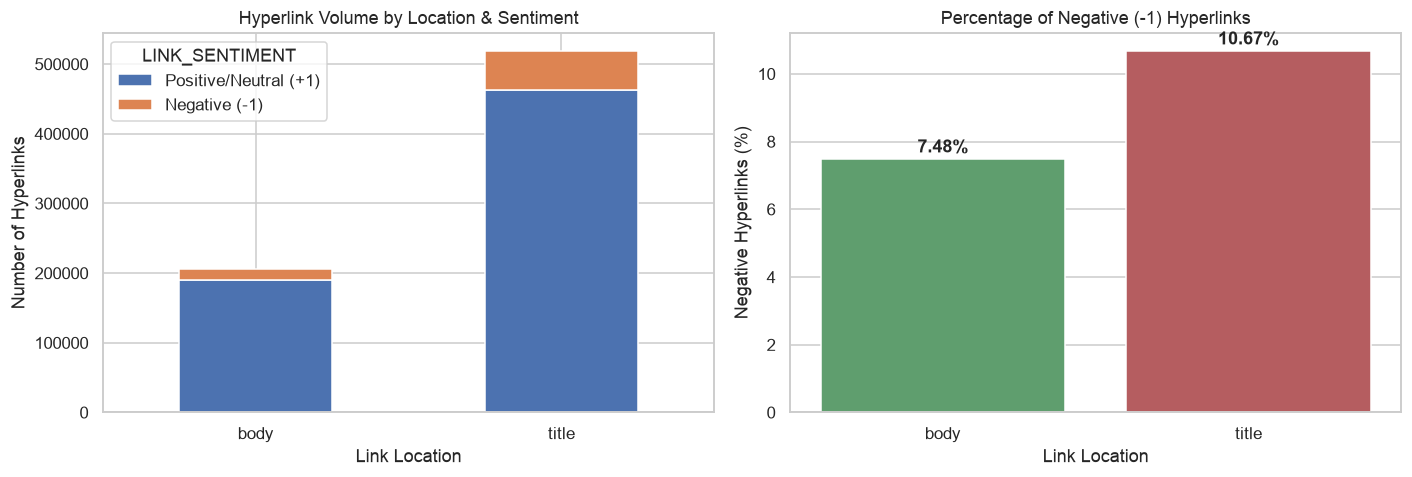

In [18]:
sentiment_stats = (
    df.groupby(['LINK_LOCATION', 'LINK_SENTIMENT'])
    .size()
    .unstack(fill_value=0)
    .rename(columns={-1: 'Negative (-1)', 1: 'Positive/Neutral (+1)'})
)
sentiment_stats['Total'] = sentiment_stats.sum(axis=1)
sentiment_stats['Negative Rate (%)'] = (
    sentiment_stats['Negative (-1)'] / sentiment_stats['Total'] * 100
).round(2)

display(sentiment_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Count plot
sentiment_stats[['Positive/Neutral (+1)', 'Negative (-1)']].plot(
    kind='bar', stacked=True, ax=axes[0], color=['#4C72B0', '#DD8452'], rot=0
)
axes[0].set_title('Hyperlink Volume by Location & Sentiment')
axes[0].set_ylabel('Number of Hyperlinks')
axes[0].set_xlabel('Link Location')

# Negative rate comparison
sns.barplot(
    x=sentiment_stats.index,
    y=sentiment_stats['Negative Rate (%)'],
    hue=sentiment_stats.index,
    legend=False,
    ax=axes[1],
    palette=['#55A868', '#C44E52']
)
axes[1].set_title('Percentage of Negative (-1) Hyperlinks')
axes[1].set_ylabel('Negative Hyperlinks (%)')
axes[1].set_xlabel('Link Location')
for i, v in enumerate(sentiment_stats['Negative Rate (%)']):
    axes[1].text(i, v + 0.2, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Temporal Dynamics
How does cross-subreddit linking evolve from 2014 to 2017, and when do conflict spikes occur?

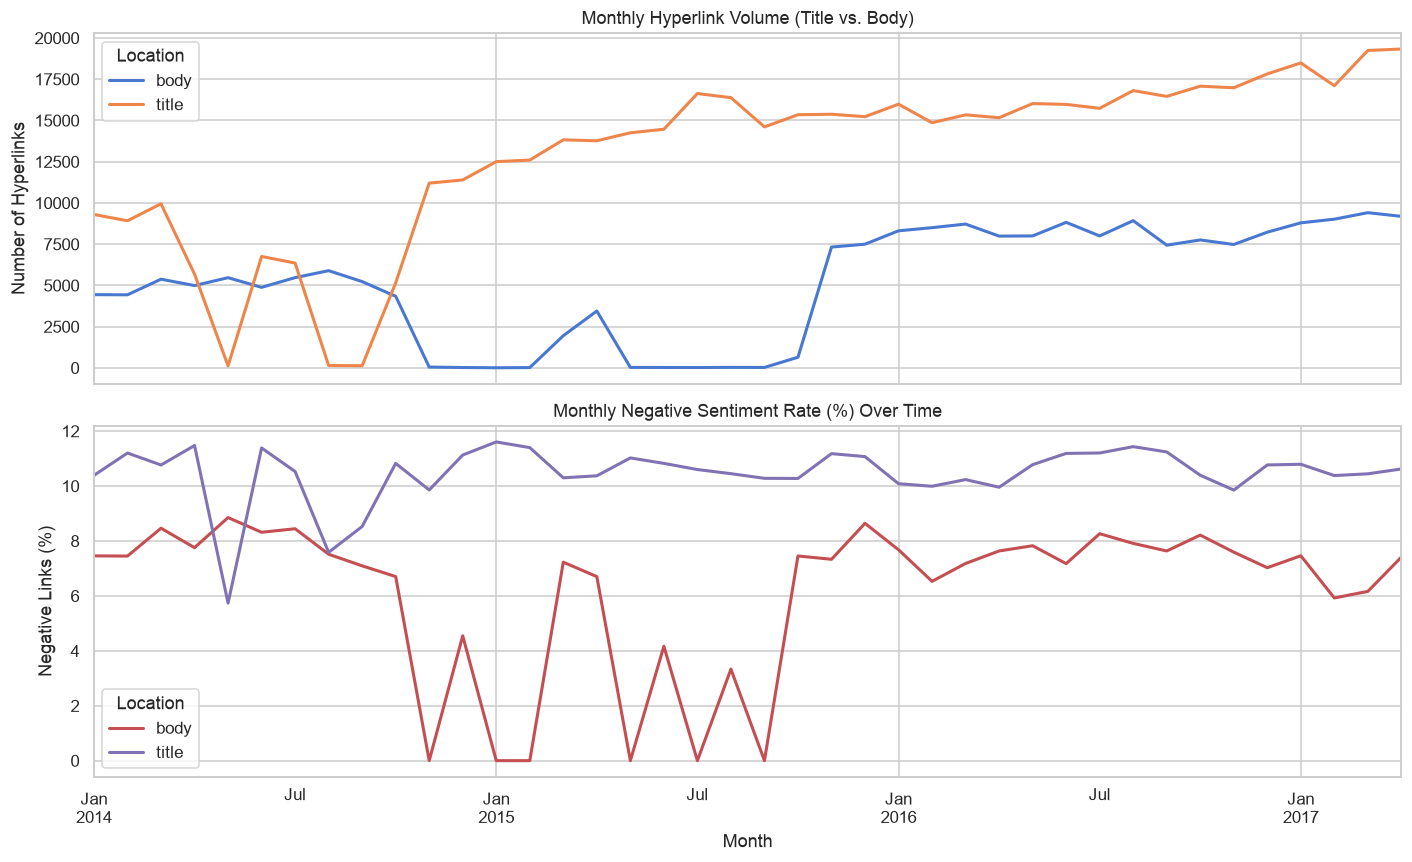

In [19]:
df['YEAR_MONTH'] = df['TIMESTAMP'].dt.to_period('M').dt.to_timestamp()
# Filter out the handful of Dec 2013 boundary rows for clean monthly plots
df_monthly = df[df['YEAR_MONTH'] >= '2014-01-01']

monthly_counts = (
    df_monthly.groupby(['YEAR_MONTH', 'LINK_LOCATION'])
    .size()
    .unstack(fill_value=0)
)
monthly_neg_rate = (
    df_monthly.groupby(['YEAR_MONTH', 'LINK_LOCATION'])['LINK_SENTIMENT']
    .apply(lambda s: (s == -1).mean() * 100)
    .unstack()
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

monthly_counts.plot(ax=axes[0], linewidth=2)
axes[0].set_title('Monthly Hyperlink Volume (Title vs. Body)')
axes[0].set_ylabel('Number of Hyperlinks')
axes[0].legend(title='Location')

monthly_neg_rate.plot(ax=axes[1], linewidth=2, color=['#C44E52', '#8172B3'])
axes[1].set_title('Monthly Negative Sentiment Rate (%) Over Time')
axes[1].set_ylabel('Negative Links (%)')
axes[1].set_xlabel('Month')
axes[1].legend(title='Location')

plt.tight_layout()
plt.show()

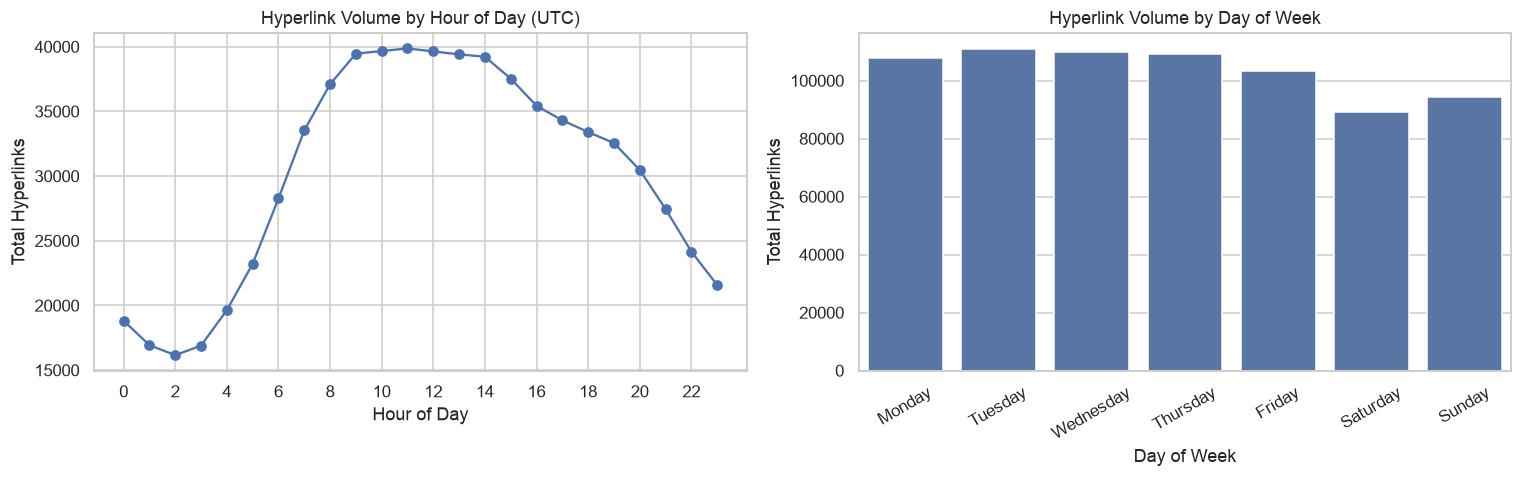

In [20]:
# Activity by Hour of Day and Day of Week
df['HOUR'] = df['TIMESTAMP'].dt.hour
df['DAY_OF_WEEK'] = df['TIMESTAMP'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

hourly = df.groupby('HOUR').agg(count=('POST_ID', 'count'), neg_rate=('LINK_SENTIMENT', lambda s: (s == -1).mean() * 100))
axes[0].plot(hourly.index, hourly['count'], marker='o', color='#4C72B0')
axes[0].set_title('Hyperlink Volume by Hour of Day (UTC)')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Total Hyperlinks')
axes[0].set_xticks(range(0, 24, 2))

dow_counts = df['DAY_OF_WEEK'].value_counts().reindex(days_order)
sns.barplot(x=dow_counts.index, y=dow_counts.values, ax=axes[1], color='#4C72B0')
axes[1].set_title('Hyperlink Volume by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Total Hyperlinks')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 4. Subreddit Network & Conflict Analysis
Which communities are the biggest hubs, which pairs of subreddits link to each other the most, and where is conflict concentrated?

/var/folders/dy/_n01rj7j2wd3dccjvzbf0htr0000gn/T/ipykernel_42858/2677748121.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_sources.values, y=top_sources.index, ax=axes[0], palette='Blues_r')
/var/folders/dy/_n01rj7j2wd3dccjvzbf0htr0000gn/T/ipykernel_42858/2677748121.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_targets.values, y=top_targets.index, ax=axes[1], palette='Greens_r')


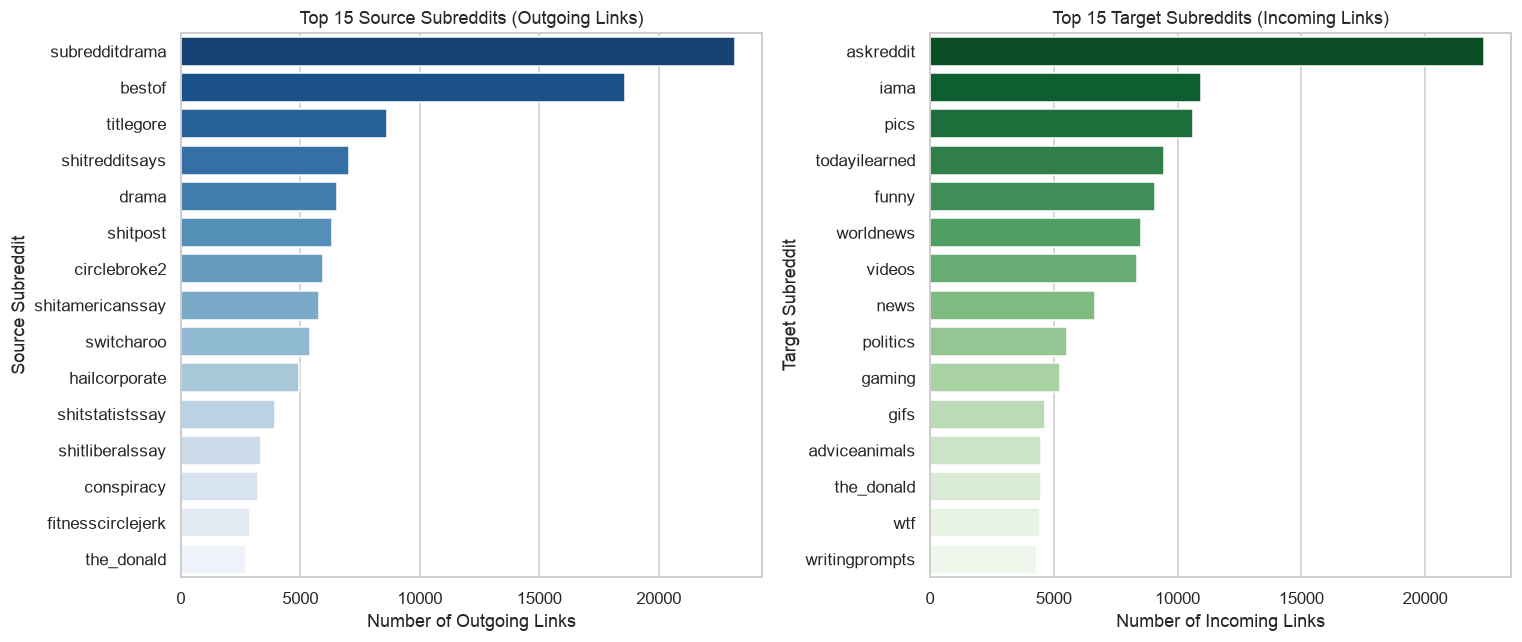

In [21]:
top_sources = df['SOURCE_SUBREDDIT'].value_counts().head(15)
top_targets = df['TARGET_SUBREDDIT'].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_sources.values, y=top_sources.index, hue=top_sources.index, legend=False, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 15 Source Subreddits (Outgoing Links)')
axes[0].set_xlabel('Number of Outgoing Links')
axes[0].set_ylabel('Source Subreddit')

sns.barplot(x=top_targets.values, y=top_targets.index, hue=top_targets.index, legend=False, ax=axes[1], palette='Greens_r')
axes[1].set_title('Top 15 Target Subreddits (Incoming Links)')
axes[1].set_xlabel('Number of Incoming Links')
axes[1].set_ylabel('Target Subreddit')

plt.tight_layout()
plt.show()

/var/folders/dy/_n01rj7j2wd3dccjvzbf0htr0000gn/T/ipykernel_42858/56583397.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_neg_sources.values, y=top_neg_sources.index, ax=axes[0], palette='Reds_r')
/var/folders/dy/_n01rj7j2wd3dccjvzbf0htr0000gn/T/ipykernel_42858/56583397.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_neg_targets.values, y=top_neg_targets.index, ax=axes[1], palette='Oranges_r')


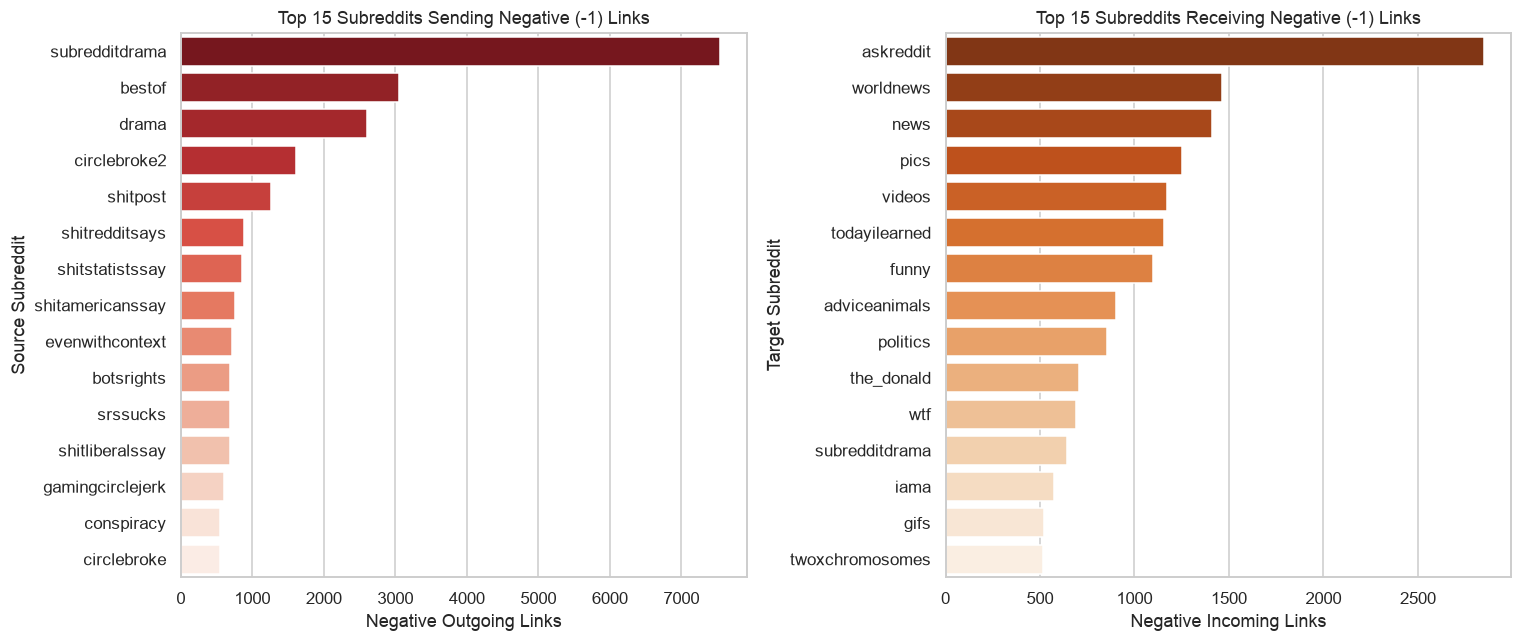

In [22]:
# Subreddits initiating and receiving the most NEGATIVE (-1) links
neg_df = df[df['LINK_SENTIMENT'] == -1]

top_neg_sources = neg_df['SOURCE_SUBREDDIT'].value_counts().head(15)
top_neg_targets = neg_df['TARGET_SUBREDDIT'].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_neg_sources.values, y=top_neg_sources.index, hue=top_neg_sources.index, legend=False, ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 15 Subreddits Sending Negative (-1) Links')
axes[0].set_xlabel('Negative Outgoing Links')
axes[0].set_ylabel('Source Subreddit')

sns.barplot(x=top_neg_targets.values, y=top_neg_targets.index, hue=top_neg_targets.index, legend=False, ax=axes[1], palette='Oranges_r')
axes[1].set_title('Top 15 Subreddits Receiving Negative (-1) Links')
axes[1].set_xlabel('Negative Incoming Links')
axes[1].set_ylabel('Target Subreddit')

plt.tight_layout()
plt.show()

In [23]:
# Top 15 Directed Subreddit Pairs and their Negative Rate
pair_stats = (
    df.groupby(['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT'])
    .agg(
        total_links=('POST_ID', 'count'),
        neg_links=('LINK_SENTIMENT', lambda s: (s == -1).sum()),
        neg_rate_pct=('LINK_SENTIMENT', lambda s: round((s == -1).mean() * 100, 2))
    )
    .sort_values('total_links', ascending=False)
    .head(15)
)
print("Top 15 Most Frequent Directed Subreddit Pairs:")
display(pair_stats)

# Top 15 Most Hostile Directed Subreddit Pairs (by volume of negative links)
hostile_pairs = (
    df.groupby(['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT'])
    .agg(
        total_links=('POST_ID', 'count'),
        neg_links=('LINK_SENTIMENT', lambda s: (s == -1).sum()),
        neg_rate_pct=('LINK_SENTIMENT', lambda s: round((s == -1).mean() * 100, 2))
    )
    .sort_values('neg_links', ascending=False)
    .head(15)
)
print("\nTop 15 Directed Subreddit Pairs with the Most Negative Links:")
display(hostile_pairs)

Top 15 Most Frequent Directed Subreddit Pairs:


,,total_links,neg_links,neg_rate_pct
SOURCE_SUBREDDIT,TARGET_SUBREDDIT,,,
moronicmondayandroid,android,414,0,0.00
trendingsubreddits,changelog,382,0,0.00
nightlypick,hockey,286,0,0.00
goodshibe,dogecoin,260,0,0.00
evenwithcontext,askreddit,258,88,34.11
drugscirclejerk,drugs,257,51,19.84
titlegore,todayilearned,246,0,0.00
shitredditsays,twoxchromosomes,237,113,47.68
badphilosophy,philosophy,231,30,12.99



Top 15 Directed Subreddit Pairs with the Most Negative Links:


total_links  neg_links  neg_rate_pct
SOURCE_SUBREDDIT   TARGET_SUBREDDIT                                       
shitredditsays     twoxchromosomes            237        113         47.68
evenwithcontext    askreddit                  258         88         34.11
subredditdrama     relationships              197         84         42.64
amrsucks           againstmensrights          168         80         47.62
subredditdrama     askreddit                  203         76         37.44
                   pics                       209         74         35.41
                   todayilearned              218         73         33.49
circlebroke2       pics                       224         68         30.36
againstkarmawhores pics                       132         68         51.52
circlebroke2       videos                     212         68         32.08
subredditdrama     videos                     197         67         34.01
againstmensrights  mensrights                 150         67         44.67
thebluepill        marriedredpill             168         65         38.69
bestoftldr         askreddit                  178         64         35.96
circlebroke2       funny                      212         64         30.19

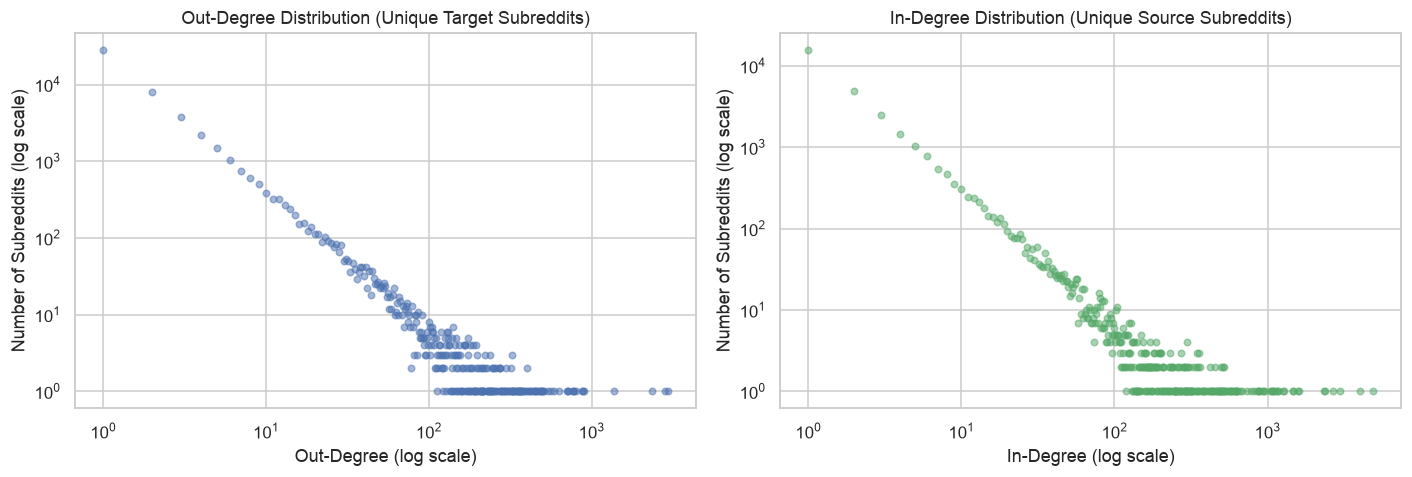

In [24]:
# Degree distribution (Out-degree vs In-degree on log-log axes)
out_deg = df.groupby('SOURCE_SUBREDDIT')['TARGET_SUBREDDIT'].nunique()
in_deg = df.groupby('TARGET_SUBREDDIT')['SOURCE_SUBREDDIT'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

out_freq = out_deg.value_counts().sort_index()
in_freq = in_deg.value_counts().sort_index()

axes[0].scatter(out_freq.index, out_freq.values, alpha=0.5, s=18, color='#4C72B0')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title('Out-Degree Distribution (Unique Target Subreddits)')
axes[0].set_xlabel('Out-Degree (log scale)')
axes[0].set_ylabel('Number of Subreddits (log scale)')

axes[1].scatter(in_freq.index, in_freq.values, alpha=0.5, s=18, color='#55A868')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('In-Degree Distribution (Unique Source Subreddits)')
axes[1].set_xlabel('In-Degree (log scale)')
axes[1].set_ylabel('Number of Subreddits (log scale)')

plt.tight_layout()
plt.show()

## 5. Unpacking the 86 `PROPERTIES` Features (Text, VADER & LIWC)
Each row's `PROPERTIES` column contains 86 comma-separated numerical values describing the source post:
1. **Surface & Readability Metrics (1–18):** Character count, word count, uppercase fraction, Automated Readability Index, etc.
2. **VADER Sentiment Scores (19–21):** Positive, Negative, and Compound sentiment.
3. **LIWC Categories (22–86):** 65 Linguistic Inquiry and Word Count lexical categories (pronouns, swear words, anger, anxiety, social processes, etc.).

Let's parse `PROPERTIES` into a clean DataFrame with the official SNAP feature names and inspect which features distinguish **negative (`-1`)** from **positive/neutral (`+1`)** links.

In [30]:
PROPERTY_NAMES = [
    'num_chars', 'num_chars_no_ws', 'frac_alpha', 'frac_digits', 'frac_upper',
    'frac_ws', 'frac_special', 'num_words', 'num_unique_words', 'num_long_words',
    'avg_word_len', 'num_unique_stopwords', 'frac_stopwords', 'num_sentences',
    'num_long_sentences', 'avg_chars_per_sentence', 'avg_words_per_sentence',
    'automated_readability_index', 'vader_pos', 'vader_neg', 'vader_compound',
    'LIWC_Funct', 'LIWC_Pronoun', 'LIWC_Ppron', 'LIWC_I', 'LIWC_We', 'LIWC_You',
    'LIWC_SheHe', 'LIWC_They', 'LIWC_Ipron', 'LIWC_Article', 'LIWC_Verbs',
    'LIWC_AuxVb', 'LIWC_Past', 'LIWC_Present', 'LIWC_Future', 'LIWC_Adverbs',
    'LIWC_Prep', 'LIWC_Conj', 'LIWC_Negate', 'LIWC_Quant', 'LIWC_Numbers',
    'LIWC_Swear', 'LIWC_Social', 'LIWC_Family', 'LIWC_Friends', 'LIWC_Humans',
    'LIWC_Affect', 'LIWC_Posemo', 'LIWC_Negemo', 'LIWC_Anx', 'LIWC_Anger',
    'LIWC_Sad', 'LIWC_CogMech', 'LIWC_Insight', 'LIWC_Cause', 'LIWC_Discrep',
    'LIWC_Tentat', 'LIWC_Certain', 'LIWC_Inhib', 'LIWC_Incl', 'LIWC_Excl',
    'LIWC_Percept', 'LIWC_See', 'LIWC_Hear', 'LIWC_Feel', 'LIWC_Bio',
    'LIWC_Body', 'LIWC_Health', 'LIWC_Sexual', 'LIWC_Ingest', 'LIWC_Relativ',
    'LIWC_Motion', 'LIWC_Space', 'LIWC_Time', 'LIWC_Work', 'LIWC_Achiev',
    'LIWC_Leisure', 'LIWC_Home', 'LIWC_Money', 'LIWC_Relig', 'LIWC_Death',
    'LIWC_Assent', 'LIWC_Dissent', 'LIWC_Nonflu', 'LIWC_Filler'
]

# Parse the 86 comma-separated floats while filtering out any corrupted rows in the raw TSVs
parsed_rows = []
valid_indices = []
malformed_indices = []

for idx, row_str in enumerate(df['PROPERTIES']):
    parts = row_str.split(',')
    if len(parts) == len(PROPERTY_NAMES):
        try:
            parsed_rows.append([float(x) for x in parts])
            valid_indices.append(idx)
        except ValueError:
            malformed_indices.append(idx)
    else:
        malformed_indices.append(idx)

props_matrix = np.array(parsed_rows, dtype=np.float32)
props_df = pd.DataFrame(props_matrix, columns=PROPERTY_NAMES)
props_df['LINK_SENTIMENT'] = df['LINK_SENTIMENT'].iloc[valid_indices].values
props_df['LINK_LOCATION'] = df['LINK_LOCATION'].iloc[valid_indices].values

print(f"Valid parsed rows   : {len(props_df):,} (skipped {len(malformed_indices)} malformed rows in raw TSVs)")
print(f"Parsed properties shape: {props_df.shape}")
display(props_df.head(5))

Valid parsed rows   : 724,706 (skipped 4 malformed rows in raw TSVs)
Parsed properties shape: (724706, 88)


,num_chars,num_chars_no_ws,frac_alpha,frac_digits,frac_upper,frac_ws,frac_special,num_words,num_unique_words,num_long_words,...,LIWC_Home,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler,LINK_SENTIMENT,LINK_LOCATION
0,25.0,23.0,0.760000,0.00,0.440000,0.120000,0.120000,4.0,4.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,title
1,100.0,88.0,0.780000,0.02,0.080000,0.130000,0.070000,16.0,16.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,title
2,100.0,88.0,0.780000,0.02,0.080000,0.130000,0.070000,16.0,16.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,title
3,49.0,43.0,0.775510,0.00,0.265306,0.142857,0.081633,8.0,8.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,title
4,14.0,14.0,0.785714,0.00,0.428571,0.071429,0.142857,2.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,title


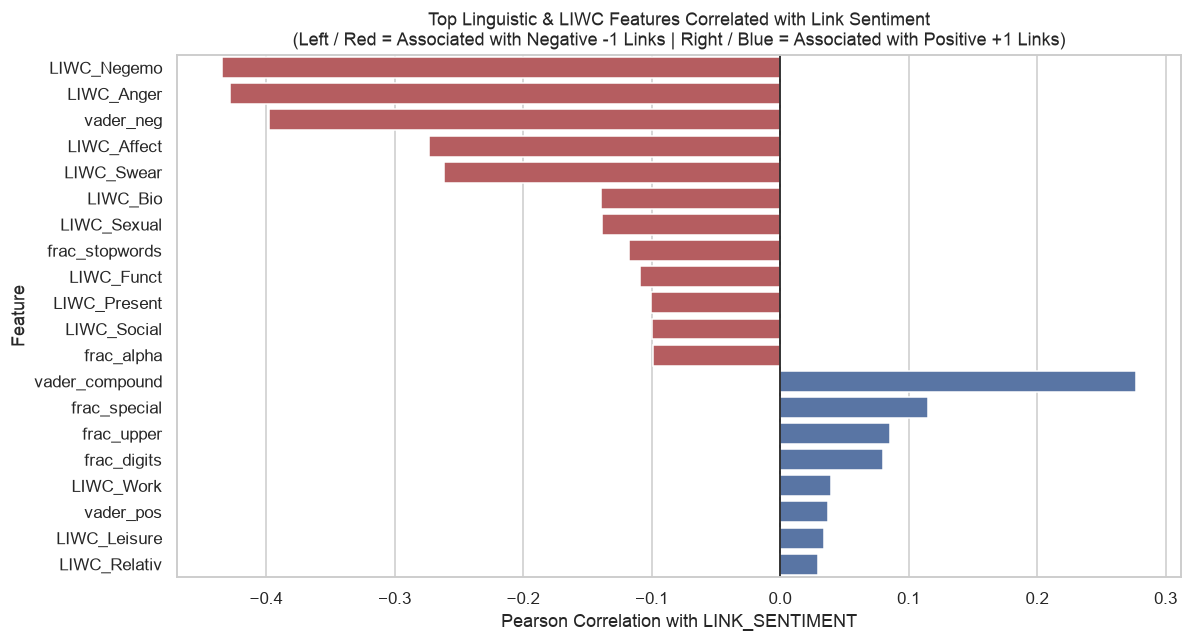

In [31]:
# Compute correlation of each property with LINK_SENTIMENT (-1 vs +1)
# Negative correlation means higher values are associated with NEGATIVE (-1) links
corrs = props_df[PROPERTY_NAMES].apply(lambda col: col.corr(props_df['LINK_SENTIMENT']))
top_corrs = pd.concat([corrs.nsmallest(12), corrs.nlargest(8)])

plt.figure(figsize=(11, 6))
colors = ['#C44E52' if v < 0 else '#4C72B0' for v in top_corrs.values]
sns.barplot(x=top_corrs.values, y=top_corrs.index, hue=top_corrs.index, legend=False, palette=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Top Linguistic & LIWC Features Correlated with Link Sentiment\n(Left / Red = Associated with Negative -1 Links | Right / Blue = Associated with Positive +1 Links)')
plt.xlabel('Pearson Correlation with LINK_SENTIMENT')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [32]:
# Compare mean values of key features across Positive (+1) and Negative (-1) links
key_features = [
    'num_words', 'frac_upper', 'vader_pos', 'vader_neg', 'vader_compound',
    'LIWC_Swear', 'LIWC_Anger', 'LIWC_Negemo', 'LIWC_Posemo',
    'LIWC_I', 'LIWC_We', 'LIWC_You', 'LIWC_They', 'LIWC_Negate'
]

comparison = props_df.groupby('LINK_SENTIMENT')[key_features].mean().T
comparison.columns = ['Negative (-1) Mean', 'Positive/Neutral (+1) Mean']
comparison['Ratio (-1 / +1)'] = (comparison['Negative (-1) Mean'] / comparison['Positive/Neutral (+1) Mean']).round(2)
display(comparison.round(4))

,Negative (-1) Mean,Positive/Neutral (+1) Mean,Ratio (-1 / +1)
num_words,95.594498,108.066704,0.88
frac_upper,0.090800,0.121600,0.75
vader_pos,0.071800,0.086600,0.83
vader_neg,0.207500,0.052300,3.97
vader_compound,-0.328600,0.134700,-2.44
LIWC_Swear,0.017200,0.001700,10.39
LIWC_Anger,0.044400,0.005300,8.44
LIWC_Negemo,0.064700,0.011800,5.46
LIWC_Posemo,0.023100,0.026200,0.88
LIWC_I,0.013200,0.014000,0.94


## 6. Key Takeaways from the Dataset
1. **Scale & Structure:** The combined network spans **~858k directed hyperlinks** across **~55.8k subreddits** from Jan 2014 to Apr 2017, with heavy-tailed (power-law) in-degree and out-degree distributions.
2. **Title vs. Body Differences:** Links in **post titles** have a substantially higher rate of negative sentiment (`-1`) than links embedded in **post bodies**, because cross-linking in titles is frequently used by meta/drama communities to call out or mobilize against target posts.
3. **Concentrated Conflict:** A small subset of meta and ideological communities accounts for a disproportionate share of negative links.
4. **Linguistic Signatures of Conflict:** Negative links (`-1`) exhibit markedly higher **VADER negativity**, **anger (`LIWC_Anger`)**, **swear words (`LIWC_Swear`)**, **negations (`LIWC_Negate`)**, and **third-person plural pronouns (`LIWC_They` — "us vs. them" framing)**, while positive/neutral links use more first-person (`LIWC_I`, `LIWC_We`) and positive emotion (`LIWC_Posemo`) language.